# Expected vs observed calibration by SDoH

This section compares the Genetic and Joint model expected model predictions vs observed case status. This compairison is made within each SDoH quintile.  

# Set up 

In [96]:
# Load packages used in the analysis. Install any missing packages if needed.
required_packages <- c("tidyverse", "readr")
missing_packages <- setdiff(required_packages, rownames(installed.packages()))
if (length(missing_packages) > 0){
  install.packages(missing_packages)
}

library(tidyverse)
library(readr)

current_directory <- "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48"
data_dir <- file.path(current_directory, "data")

#Load demographic data
demo_file = paste0(current_directory, "/data/Demographic_and_ancestry_covariates.csv")
demo  <- read_csv(demo_file) |> 
    select(-c(income, education)) |> 
    rename(age = age_at_last_event)

#Load SES data
ses_file = paste0(current_directory, "/data/SES_data.csv")
ses_data  <- read_csv(ses_file)

#MERGE
demo_sdoh<-merge(demo, ses_data, on="person_id", how="inner")

#Load PRS data
PRS_file = paste0(current_directory, "/data/adjusted_PRS_scores.csv")
PRS  <- read_csv(PRS_file) 

#Load Case control info 
name_of_file_in_bucket <- 'Case_Control_df.csv'
system(paste0("gsutil cp gs://rw-migration-aou-rw-55feedb6/notebooks/Case_Control_df.csv ."), intern=T)
case_control  <- read_csv(name_of_file_in_bucket)

merged_data<-merge(PRS, case_control, on="person_id", how="left")
merged_data<-merge(merged_data, demo_sdoh, on="person_id", how="left")

merged_data <- merged_data %>%
  mutate(
    SexGenderCis_male = ifelse(SexGender == "Cis_male", 1, 0),
    SexGenderCis_female = ifelse(SexGender == "Cis_female", 1, 0),
    SexGenderSGM = ifelse(SexGender == "SGM", 1, 0)
  )

merged_data$age2<-merged_data$age^2

predictions_unadjusted <- read_csv(file.path(data_dir, "oof_genetic_joint_predictions.csv"), show_col_types = FALSE)
predictions_pc_adjusted <- read_csv(file.path(data_dir, "oof_genetic_joint_predictions_PCs.csv"), show_col_types = FALSE)

selection_terms <- c(
  "individual_poverty", "education", "fraction_assisted_income",
  "fraction_no_high_school_education", "lower_median_income",
  "fraction_no_health_insurance", "fraction_poverty",
  "fraction_vacant_housing", "deprivation_index"
)


diseases<-c("Asthma", "Afib", "BreastC", "CKD", "CHD", "ProstateC", "t2d", "t1d")

disease_name_mapping <- c(
    "Asthma" = "Asthma",
    "Afib" = "Afib",
    "CKD" = "CKD", 
    "CHD" = "CHD",
  "t2d" = "T2D",
  "t1d" = "T1D",
    "BreastC" = "Breast\nCancer",
    "ProstateC" = "Prostate\nCancer"
)

disease_order <- c("Breast\nCancer", "Prostate\nCancer", "Afib", "T2D","CKD", "CHD", "Asthma", "T1D")


domain_name_mapping <- c(
    "individual_poverty" = "Individual Poverty",
    "education" = "Lower Individual Education", 
    "fraction_assisted_income" = "Assisted Income (%)",
  "fraction_no_high_school_education" = "No High School Education (%)",
  "lower_median_income" = "Lower Median Income",
    "fraction_no_health_insurance" = "No Health Insurance (%)",
    "fraction_poverty" = "Poverty (%)",
    'fraction_vacant_housing' = "Vacant Housing (%)",
    'deprivation_index' = "Deprivation Index"
)

domain_name_mapping_spaced <- c(
    "individual_poverty" = "Individual\nPoverty",
    "education" = "Lower Individual\nEducation", 
    "fraction_assisted_income" = "Assisted\nIncome (%)",
  "fraction_no_high_school_education" = "No High School\nEducation (%)",
  "lower_median_income" = "Lower\nMedian Income",
    "fraction_no_health_insurance" = "No Health\nInsurance (%)",
    "fraction_poverty" = "Poverty (%)",
    'fraction_vacant_housing' = "Vacant\nHousing (%)",
    'deprivation_index' = "Deprivation\nIndex"
)

Domain_order <-c('Lower Individual\nEducation', 'Individual\nPoverty',
         'Assisted\nIncome (%)', 'No High School\nEducation (%)', 'Lower\nMedian Income', 
         'No Health\nInsurance (%)', 'Poverty (%)', 'Vacant\nHousing (%)', 'Deprivation\nIndex')

Domain_order_long <-c('Lower Individual Education', 'Individual Poverty',
         'Assisted Income (%)', 'No High School Education (%)', 'Lower Median Income', 
         'No Health Insurance (%)', 'Poverty (%)', 'Vacant Housing (%)', 'Deprivation Index')

Rows: 135557 Columns: 51
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (9): SexGender, ancestry_pred, education, where_born, military, health...
dbl  (30): person_id, race_unknown, age_today, PC_1, PC_2, PC_3, PC_4, PC_5,...
lgl   (8): AIAN, Asian, Black, Mid, Multiple, PI, White, His
dttm  (1): basics_survey_datetime
date  (3): date_of_birth, min_date, max_date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 214915 Columns: 13
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (13): person_id, income, education, per_poverty_threshold, individual_po...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 135557 Columns: 9
── Column specification ────────────────────

character(0)

Rows: 265954 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma, Afib, BreastC, CKD, CHD, HyperC, ProstateC, t2d...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


# Calibrate within SDoH quintiles

In [113]:
summarize_calibration_by_sdoh <- function(prediction_data, analysis_label, sdoh_data, sdoh_variables, output_dir) {
  # Keep participants with paired out-of-fold Genetic and Joint predictions so
  # the stratum cut points and observed outcomes are identical across models.
  paired_predictions <- prediction_data %>%
    filter(Model %in% c("Genetic", "Joint")) %>%
    transmute(
      person_id,
      Disease = as.character(Disease),
      Model = as.character(Model),
      actual = as.numeric(as.character(actual)),
      prediction = as.numeric(prediction)
    ) %>%
    filter(is.finite(actual), is.finite(prediction), actual %in% c(0, 1), prediction >= 0, prediction <= 1) %>%
    tidyr::pivot_wider(
      id_cols = c(person_id, Disease, actual),
      names_from = Model,
      values_from = prediction
    ) %>%
    filter(is.finite(Genetic), is.finite(Joint))

  sdoh_data <- sdoh_data %>%
    select(person_id, all_of(sdoh_variables)) %>%
    distinct(person_id, .keep_all = TRUE)

  paired_with_sdoh <- paired_predictions %>%
    inner_join(sdoh_data, by = "person_id")

  expected_observed <- purrr::map_dfr(sdoh_variables, function(sdoh_variable) {
    paired_with_sdoh %>%
      filter(!is.na(.data[[sdoh_variable]])) %>%
      group_by(Disease) %>%
      mutate(SDoH_Quintile = dplyr::ntile(.data[[sdoh_variable]], 5)) %>%
      ungroup() %>%
      select(person_id, Disease, actual, SDoH_Quintile, Genetic, Joint) %>%
      pivot_longer(
        cols = c(Genetic, Joint),
        names_to = "Model",
        values_to = "prediction"
      ) %>%
      group_by(Disease, Model, SDoH_Quintile) %>%
      summarise(
        n = n(),
        observed_cases = sum(actual),
        expected_cases = sum(prediction),
        observed_risk = mean(actual),
        expected_risk = mean(prediction),
        observed_expected_ratio = if (sum(prediction) > 0) sum(actual) / sum(prediction) else NA_real_,
        brier_score = mean((actual - prediction)^2),
        .groups = "drop"
      ) %>%
      mutate(SDoH_Variable = sdoh_variable, .before = 1)
  }) %>%
    mutate(Analysis = analysis_label, .before = 1) %>%
    arrange(SDoH_Variable, Disease, SDoH_Quintile, Model)

      # Direct paired contrasts summarize how predictions and calibration differ
  # between the Joint and Genetic models within the same disease/SDoH stratum.
  model_comparison <- expected_observed %>%
    select(Analysis, SDoH_Variable, Disease, SDoH_Quintile, Model,
           expected_risk, observed_risk, observed_expected_ratio, brier_score) %>%
    pivot_wider(
      names_from = Model,
      values_from = c(expected_risk, observed_risk, observed_expected_ratio, brier_score),
      names_sep = "_"
    ) %>%
    mutate(
      Joint_minus_Genetic_expected_risk = expected_risk_Joint - expected_risk_Genetic,
      Joint_minus_Genetic_OE_ratio = observed_expected_ratio_Joint - observed_expected_ratio_Genetic,
      Joint_minus_Genetic_Brier = brier_score_Joint - brier_score_Genetic
    )

  expected_observed_clean <- expected_observed |>
    mutate(SDoH_Variable = recode(SDoH_Variable, !!!domain_name_mapping_spaced, .default = SDoH_Variable)) |>
    mutate(Disease = recode(Disease, !!!disease_name_mapping, .default = Disease)) |>
     mutate(SDoH_Variable = factor(SDoH_Variable, levels = Domain_order)) |>
    mutate(Disease = factor(Disease, levels = disease_order))

  write_excel_csv(expected_observed_clean, file.path(output_dir, paste0("expected_vs_observed_by_sdoh_", analysis_label, ".csv")))
  write_excel_csv(model_comparison, file.path(output_dir, paste0("genetic_vs_joint_calibration_by_sdoh_", analysis_label, ".csv")))

  calibration_plot <- ggplot(
      expected_observed_clean,
      aes(
    x = factor(SDoH_Quintile),
    y = observed_expected_ratio,
    color = Model,
    group = Model
      )
    ) +
  geom_hline(yintercept = 1, linetype = "dashed", color = "grey40") +
  geom_line(linewidth = 0.7) +
  geom_point(aes(size = n), alpha = 0.85) +
  facet_grid(SDoH_Variable ~ Disease, switch = "y") +
  scale_color_manual(values = c("Genetic" = "#0072B2", "Joint" = "#D55E00")) +
  labs(
    title = paste("Observed to Expected Ratio by SDoH quintile:", analysis_label),
    x = "SDoH vulnerability quintile (1 = lowest, 5 = highest)",
    y = "Observed/Expected (positive = underprediction)",
    color = "Model",
    size = "Participants"
  ) +
  theme_minimal(base_size = 20) +
  theme(axis.text.x = element_text(angle = 0, hjust = 0.5),
       legend.position = "bottom")

  ece_by_quintile <- expected_observed %>%
  group_by(Analysis, SDoH_Variable, Disease, Model) %>%
  mutate(
    stratum_weight = n / sum(n),
    ece_contribution = stratum_weight * abs(expected_risk - observed_risk)
  ) %>%
  mutate(ECE = sum(ece_contribution)) %>%
  ungroup()

  # Overall ECE for each disease, SDoH variable, and model
  ece_summary <- ece_by_quintile %>%
    distinct(Analysis, SDoH_Variable, Disease, Model, ECE)


  ece_summary <- ece_summary |>
    mutate(SDoH_Variable = recode(SDoH_Variable, !!!domain_name_mapping, .default = SDoH_Variable)) |>
    mutate(Disease = recode(Disease, !!!disease_name_mapping, .default = Disease)) |>
     mutate(SDoH_Variable = factor(SDoH_Variable, levels = Domain_order_long)) |>
    mutate(Disease = factor(Disease, levels = disease_order))

  ece_plot <- ggplot(
  ece_summary,
  aes(x = SDoH_Variable, y = ECE, color = Model)
) +
  geom_point(
    position = position_dodge(width = 0.6),
    size = 2.5
  ) +
  facet_wrap(ece_summary$Disease, ncol=4) +
  scale_color_manual(values = c("Genetic" = "#0072B2", "Joint" = "#D55E00")) +
  coord_cartesian(ylim = c(0, max(ece_summary$ECE))) +
  labs(
    title = "Expected Calibration Error by disease and SDoH variable",
    x = "",
    y = "Expected Calibration Error (lower is better)",
    color = "Model"
  ) +
  theme_minimal(base_size = 20) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1),
       legend.position = "bottom")


  ggsave(
    filename = file.path(output_dir, paste0("expected_vs_observed_by_sdoh_", analysis_label, ".png")),
    plot = calibration_plot,
    width = 18,
    height = 16,
    dpi = 300
  )


  list(summary = expected_observed_clean, comparison = model_comparison, plot = calibration_plot, ece_summary = ece_summary, ece = ece_plot)
}


In [106]:
calibration_sdoh_oof <- summarize_calibration_by_sdoh(
  predictions_unadjusted,
  "Without_PC_adjustment",
  merged_data,
  selection_terms,
  data_dir
)

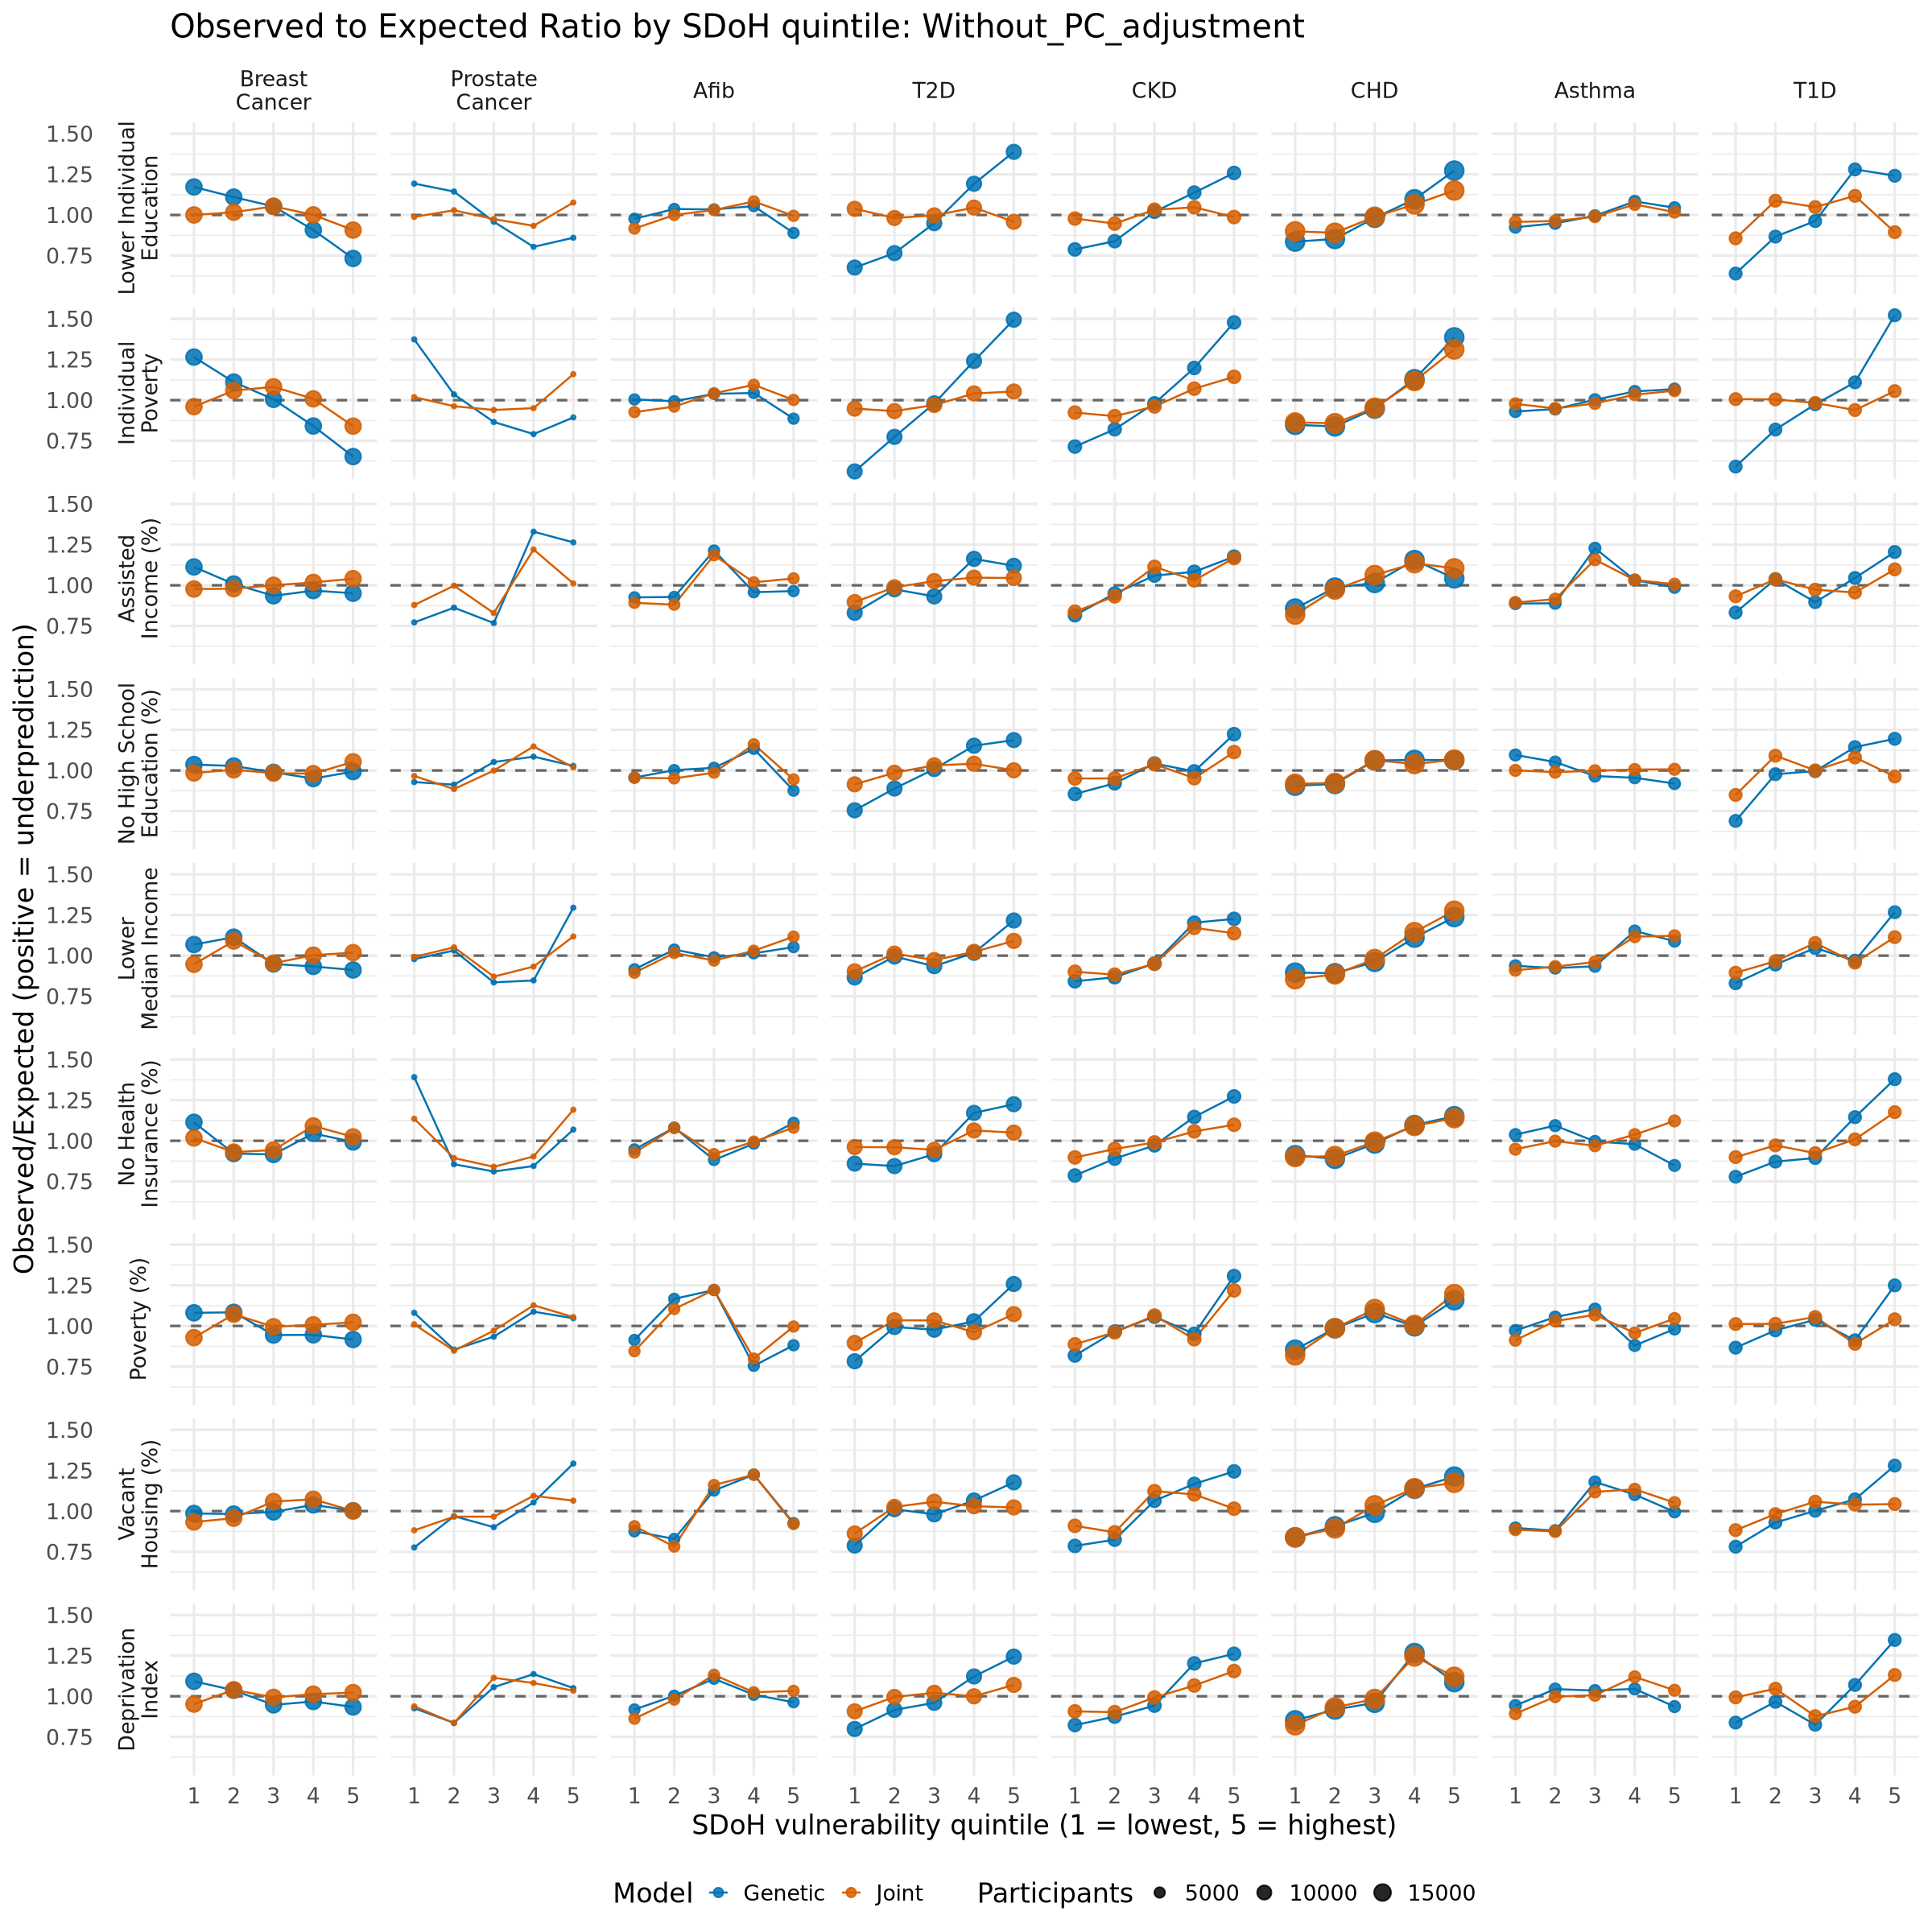

In [107]:
options(repr.plot.width = 20, repr.plot.height = 20)  # Set width and height
calibration_sdoh_oof$plot

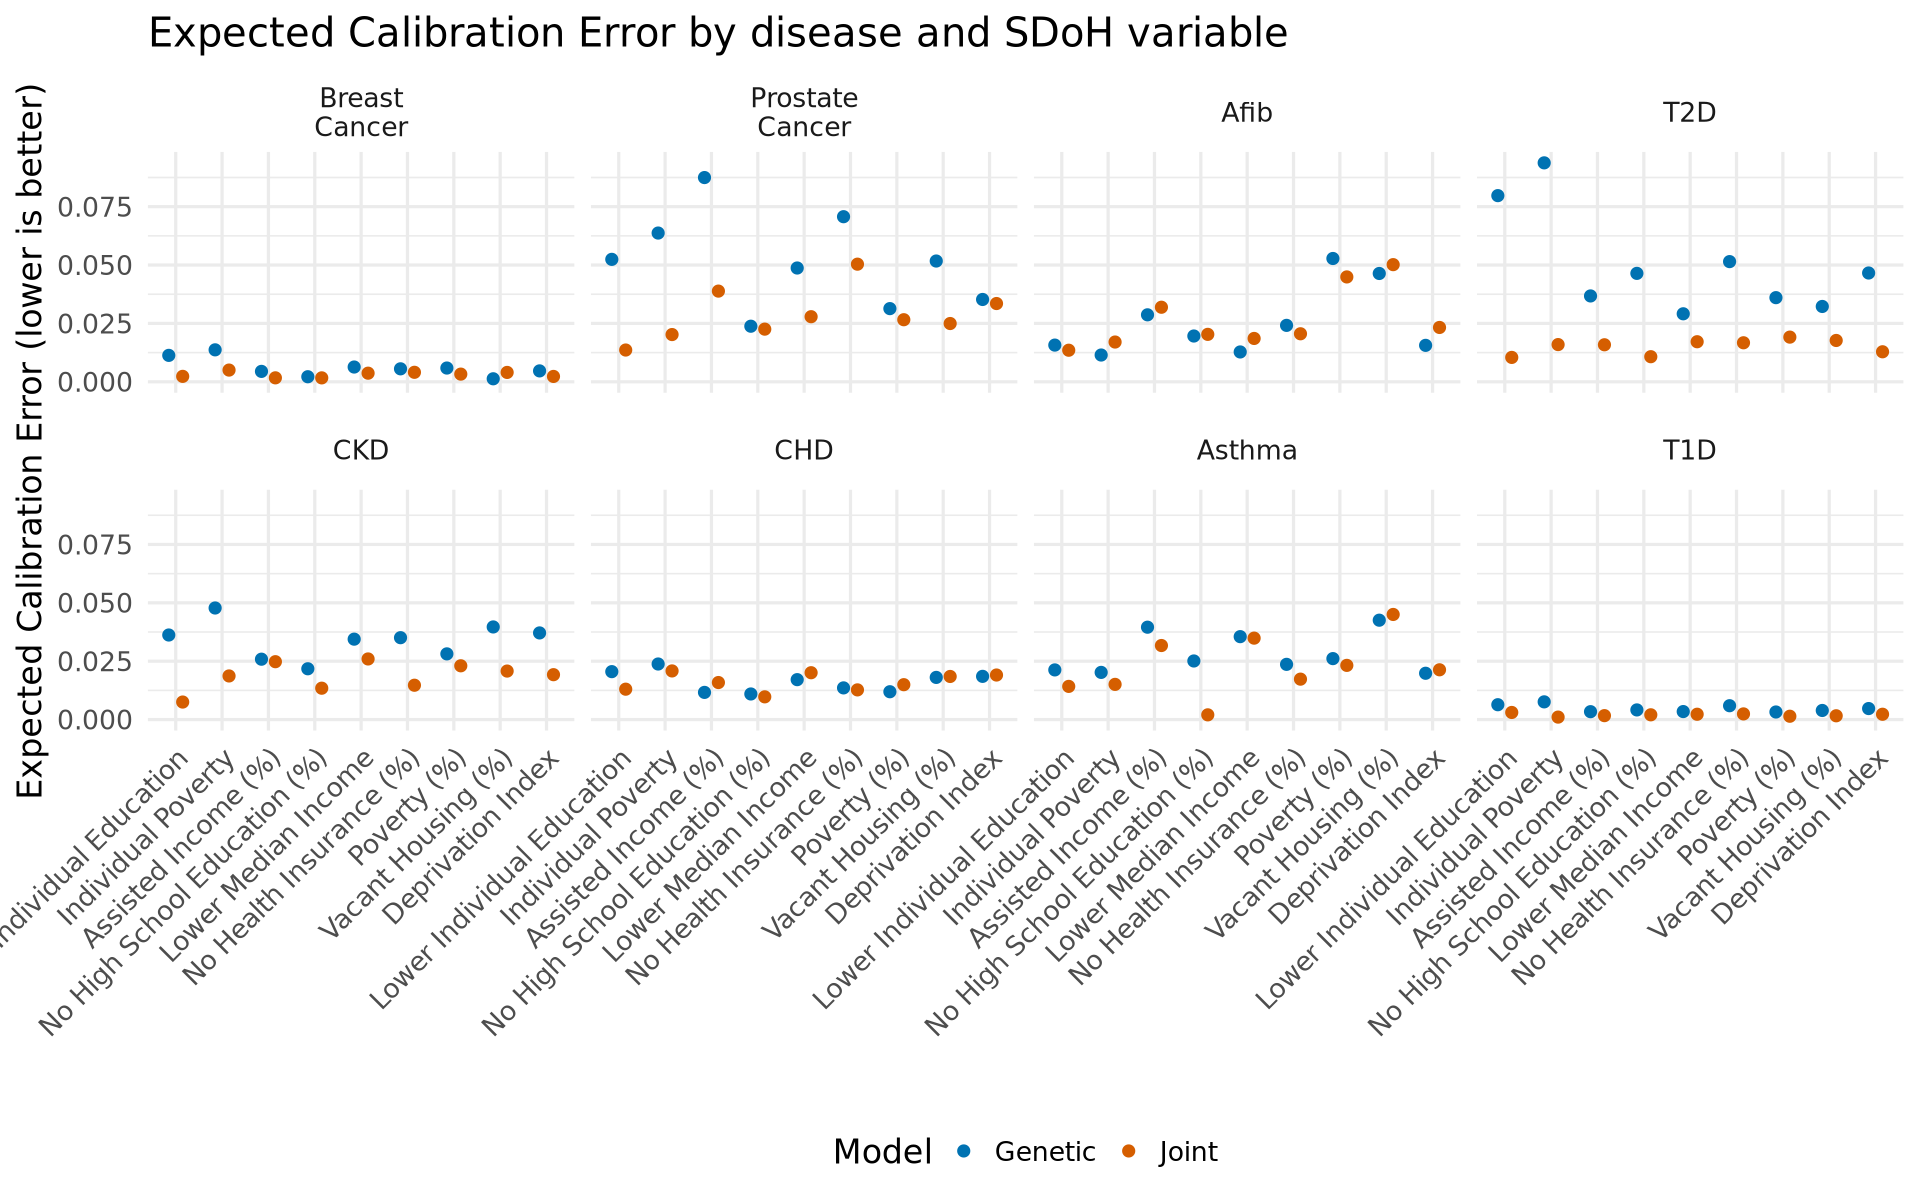

In [112]:
options(repr.plot.width = 16, repr.plot.height = 10)  # Set width and height
calibration_sdoh_oof$ece

In [114]:
calibration_sdoh_oof <- summarize_calibration_by_sdoh(
  predictions_unadjusted,
  "Without_PC_adjustment",
  merged_data,
  selection_terms,
  data_dir
)

calibration_sdoh_oof_PCs <- summarize_calibration_by_sdoh(
  predictions_pc_adjusted,
  "With_PC_adjustment",
  merged_data,
  selection_terms,
  data_dir
)

calibration_sdoh_all <- bind_rows(calibration_sdoh_oof$summary, calibration_sdoh_oof_PCs$summary)
ECE_all <- bind_rows(calibration_sdoh_oof$ece_summary, calibration_sdoh_oof_PCs$ece_summary)
calibration_sdoh_comparison_all <- bind_rows(calibration_sdoh_oof$comparison, calibration_sdoh_oof_PCs$comparison)
write_excel_csv(calibration_sdoh_all, file.path(data_dir, "expected_vs_observed_by_sdoh_all_analyses.csv"))
write_excel_csv(ECE_all, file.path(data_dir, "expected_vs_observed_by_sdoh_all_analyses_ece.csv"))
write_excel_csv(calibration_sdoh_comparison_all, file.path(data_dir, "genetic_vs_joint_calibration_by_sdoh_all_analyses.csv"))
